<a href="https://colab.research.google.com/github/24234145/data-science-toolkit/blob/main/Tutorial_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Find some real dataset. Load it on Colab, Kaggle etc. Try to visualize some of it

# 2. Evaluate if the data is good or not. Does it have enough samples?


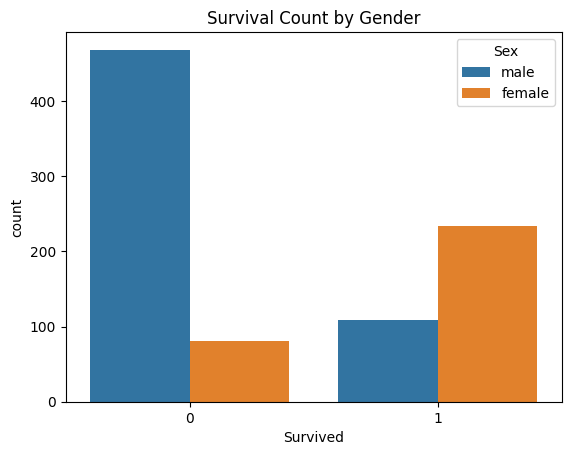

In [42]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x='Survived', hue='Sex')
plt.title("Survival Count by Gender")
plt.show()

In [43]:
import pandas as pd
df = pd.read_csv('/train.csv')
display(df.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [21]:
print("Rows and columns:", df.shape)
print ("Repeated PassengerId values:", df["PassengerId"].duplicated().sum())
print ("Survived values (0 = No, 1 = Yes):")
print(df["Survived"].value_counts())

Rows and columns: (891, 12)
Repeated PassengerId values: 0
Survived values (0 = No, 1 = Yes):
Survived
0    549
1    342
Name: count, dtype: int64


**Each row represents one passenger. Each column contains one variable (such as age or ticket fare). This is a tidy table in the basic sense: one passenger per row and one variable per column**
# 3. How many features does it have? Is it enough?

In [23]:
print("All columns:")
print(df.columns.tolist())
print("Number of columns:", len(df.columns))
print("Possible input columns (excluding Survived):", len(df.columns) - 1)

All columns:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Number of columns: 12
Possible input columns (excluding Survived): 11


**There are 12 columns: one outcome (Survived) and 11 other columns.**
# 4. How many samples/observation does it have? Is it enough?

In [24]:
print("Number of passengers:", len (df))

Number of passengers: 891


**Answer: 891 observations in the standard Kaggle train.csv. That is enough to call whether it is sufficient for a reliable prediction model depends.**
# 5. What are the datatypes does the dataset consist of?

In [25]:
print(df.dtypes)

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


**Explain: int64 means whole numbers (e.g., number of family members); float64 means decimal numbers (e.g., age or fare); and object usually means text (e.g., passenger name or sex).**

## 6. How many columns have null values? If yes, which column, which rows
## 8. Does it have missing values? If yes, which column, which row.

In [29]:
missing = df.isnull().sum()
print("Missing values in each column:")
print(missing)
print("\nColumns with any missing values:")
print(missing[missing > 0])
print("\nNumber of columns with missing values:", (missing > 0).sum())

Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Columns with any missing values:
Age         177
Cabin       687
Embarked      2
dtype: int64

Number of columns with missing values: 3


In [31]:
rows_missing = df [df.isnull().any(axis=1)]
print("Number of rows with at least one missing value:", len(rows_missing))
print("First 10 rows containing missing values:")
display(rows_missing.head(10))
column_to_check = "Age"
print("Passenger IDs with missing", column_to_check, ":")
print(df.loc[df[column_to_check].isnull(), "PassengerId"].tolist())

Number of rows with at least one missing value: 708
First 10 rows containing missing values:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C
12,13,0,3,"Saundercock, Mr. William Henry",male,20.0,0,0,A/5. 2151,8.0500,NaN,S
13,14,0,3,"Andersson, Mr. Anders Johan",male,39.0,1,5,347082,31.2750,NaN,S
14,15,0,3,"Vestrom, Miss. Hulda Amanda Adolfina",female,14.0,0,0,350406,7.8542,NaN,S


Passenger IDs with missing Age :
[6, 18, 20, 27, 29, 30, 32, 33, 37, 43, 46, 47, 48, 49, 56, 65, 66, 77, 78, 83, 88, 96, 102, 108, 110, 122, 127, 129, 141, 155, 159, 160, 167, 169, 177, 181, 182, 186, 187, 197, 199, 202, 215, 224, 230, 236, 241, 242, 251, 257, 261, 265, 271, 275, 278, 285, 296, 299, 301, 302, 304, 305, 307, 325, 331, 335, 336, 348, 352, 355, 359, 360, 365, 368, 369, 376, 385, 389, 410, 411, 412, 414, 416, 421, 426, 429, 432, 445, 452, 455, 458, 460, 465, 467, 469, 471, 476, 482, 486, 491, 496, 498, 503, 508, 512, 518, 523, 525, 528, 532, 534, 539, 548, 553, 558, 561, 564, 565, 569, 574, 579, 585, 590, 594, 597, 599, 602, 603, 612, 613, 614, 630, 634, 640, 644, 649, 651, 654, 657, 668, 670, 675, 681, 693, 698, 710, 712, 719, 728, 733, 739, 740, 741, 761, 767, 769, 774, 777, 779, 784, 791, 793, 794, 816, 826, 827, 829, 833, 838, 840, 847, 850, 860, 864, 869, 879, 889]


**Answer(standard Kaggle train.csv): Missing values occur in 3 columns: Age (177), Cabin (687), and Embarked (2). The code shows the actual rows; their row indexes are not the same thing as Passenger Id. Do not simply delete every row with a missing value without first thinking about what that would remove.**
# 7. Which column is the feature, which is the target output?

In [38]:
target = "Survived"
features = df.drop(columns=["Survived", "PassengerId"])

print("Target:", target)
print("Example feature columns:", features.columns.tolist())
print("Target values:", df[target].unique())

Target: Survived
Example feature columns: ['Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Target values: [0 1]


**Answer: The target is Survived (O = did not survive; 1 = survived). The features are passenger details used to investigate survival. PassengerId is excluded from our example features because it identifies a passenger rather than describing their circumstances. No prediction model is trained in this exercise.**
# 9. What kind of question can be asked, should we ask. Does the dataset suits the question we are asking?


In [41]:
print("Q: Which gender had a higher survival rate?")
print("Q: Did paying a higher Fare increase the chance of survival?")
print("Dataset suitability: Highly suitable for these classification questions.")

Q: Which gender had a higher survival rate?
Q: Did paying a higher Fare increase the chance of survival?
Dataset suitability: Highly suitable for these classification questions.
